# EIS parameter sensitivity

[Hallemans et al. (2025)](https://doi.org/10.1149/1945-7111/add41b) showed that, at zero DC current, the impedance of the single particle model with electrolyte (SPMe) depends on the physical parameters only through a small set of *grouped* parameters: time scales, capacitances and ratios. In their Fig. 8 they scale each grouped parameter from half to twice its value and show how the Nyquist plot changes.

In this notebook we reproduce that sensitivity study with PyBaMM's `EISSimulation`, and extend it with a solid electrolyte interphase (SEI) film on the negative electrode that has its own resistance and capacitance. We:
1. Set up an SPMe with double-layer capacitance, contact resistance and an SEI film
2. Define the grouped parameters, including two new groups for the SEI film
3. Sweep each grouped parameter, keeping all the others fixed, and plot the impedance
4. Sweep the two SEI groups over a wider range

In [1]:
%pip install "pybamm[plot,cite]" -q    # install PyBaMM if it is not installed
import matplotlib.pyplot as plt
import numpy as np

import pybamm

## Model and parameters

EIS simulations need the double-layer capacitance, which we get with `"surface form": "differential"`. We add a series contact resistance with `"contact resistance": "true"`, and a constant-thickness SEI layer on the negative electrode with `"SEI": "constant"`.

By default the SEI film only adds a resistance $\rho_{SEI} L_{SEI}$ (per unit area) in series with the charge-transfer resistance. Both then sit behind the same double-layer capacitance, so the film makes the charge-transfer arc bigger without changing its shape. Setting `"SEI film capacitance": "true"` puts a capacitance $\varepsilon_{SEI} \varepsilon_0 / L_{SEI}$ (per unit area) in parallel with the film resistance, in series with the double layer ([Meyers et al. (2000)](https://doi.org/10.1149/1.1393627)). The film overpotential $\eta_{SEI}$ then evolves as

$$
\frac{\varepsilon_{SEI} \varepsilon_0}{L_{SEI}} \frac{\partial \eta_{SEI}}{\partial t} = -j_{tot} - \frac{\eta_{SEI}}{\rho_{SEI} L_{SEI}},
$$

where $j_{tot}$ is the total current density crossing the interface, $\rho_{SEI}$ is the SEI resistivity and $\varepsilon_{SEI}$ is its relative permittivity.

We use the `Chen2020` parameter set with a 10 mΩ contact resistance. As in Hallemans et al., we take a constant electrolyte diffusivity and make the electrolyte and electrode conductivities very large, so that the series resistance is just the contact resistance. The remaining SEI parameters come from `OKane2022`, with the SEI resistivity and permittivity chosen so that the SEI arc appears just below 1 kHz.

In [2]:
model = pybamm.lithium_ion.SPMe(
    options={
        "surface form": "differential",
        "contact resistance": "true",
        "SEI": "constant",
        "SEI film capacitance": "true",
    }
)

parameter_values = pybamm.ParameterValues("Chen2020")
okane2022 = pybamm.ParameterValues("OKane2022")
parameter_values.update(
    {k: v for k, v in okane2022.items() if "SEI" in k}, check_already_exists=False
)
parameter_values.update(
    {
        "Contact resistance [Ohm]": 0.01,
        "Electrolyte diffusivity [m2.s-1]": 1.769e-10,
        "Electrolyte conductivity [S.m-1]": 1e16,
        "Negative electrode conductivity [S.m-1]": 1e16,
        "Positive electrode conductivity [S.m-1]": 1e16,
        "SEI resistivity [Ohm.m]": 4e6,
        "SEI relative permittivity": 5.0,
    },
    check_already_exists=False,
)

## Grouped parameters

The grouped parameters of Hallemans et al. are listed below, with $\pm$ referring to the positive and negative electrodes. Here $R_\pm$ is the particle radius, $D_\pm$ the particle diffusivity, $c^{max}_\pm$ the maximum particle concentration, $\alpha_\pm$ the active material volume fraction, $\varepsilon_\pm$ and $\varepsilon_{sep}$ the porosities, $b_\pm$ and $b_{sep}$ the Bruggeman coefficients, $L_\pm$ the electrode thicknesses, $L$ the cell thickness, $A$ the electrode area, $c_{e0}$ the initial electrolyte concentration, $D_e$ the electrolyte diffusivity, $C_{dl,\pm}$ the double-layer capacity and $j_{0,\pm}$ the exchange-current density, evaluated at $c_{e0}$ and $c^{max}_\pm/2$.

| Group | Definition | Meaning |
|---|---|---|
| $R_0$ | $R_{contact}$ | series resistance (the conductivities are taken as infinite) |
| $\tau_d^\pm$ | $R_\pm^2 / D_\pm$ | particle diffusion time scale [s] |
| $\tau_{ct}^\pm$ | $F c^{max}_\pm R_\pm / (2 j_{0,\pm})$ | charge-transfer time scale [s] |
| $C^\pm$ | $3 \alpha_\pm C_{dl,\pm} L_\pm A / R_\pm$ | double-layer capacitance of the electrode [F] |
| $\tau_e$ | $\varepsilon_{sep} L^2 / (\varepsilon_{sep}^{b_{sep}} D_e)$ | electrolyte diffusion time scale [s] |
| $\beta^\pm$ | $\varepsilon_\pm^{b_\pm} / \varepsilon_{sep}^{b_{sep}}$ | relative transport efficiency [-] |
| $\zeta^\pm$ | $\varepsilon_\pm / \varepsilon_{sep}$ | relative porosity [-] |
| $Q_e$ | $F \varepsilon_{sep} c_{e0} L A$ | reference electrolyte capacity [A s] |
| $t^+$ | $t^+$ | cation transference number [-] |

For the SEI film on the negative electrode we define two new groups, following the same pattern as the double layer:

| Group | Definition | Meaning |
|---|---|---|
| $\tau_{SEI}$ | $\rho_{SEI} \varepsilon_{SEI} \varepsilon_0$ | SEI film time constant [s] |
| $C_{SEI}$ | $3 \alpha_- \varepsilon_{SEI} \varepsilon_0 L_- A / (R_- L_{SEI})$ | SEI film capacitance of the electrode [F] |

$C_{SEI}$ is the film capacitance per unit area, $\varepsilon_{SEI} \varepsilon_0 / L_{SEI}$, multiplied by the active surface area of the electrode, $3 \alpha_- L_- A / R_-$, just as $C^-$ is built from $C_{dl,-}$. $\tau_{SEI}$ is the product of the film's resistance and capacitance per unit area, $\rho_{SEI} L_{SEI} \times \varepsilon_{SEI} \varepsilon_0 / L_{SEI}$. A thicker film has a larger resistance but a smaller capacitance, so the thickness cancels: $\tau_{SEI}$ is the dielectric relaxation time of the film material. The thickness changes the size of the SEI arc, through $C_{SEI}$, but not its frequency. Together, $\tau_{SEI}$ and $C_{SEI}$ fix the film resistance of the whole electrode,

$$
R_{SEI} = \frac{\tau_{SEI}}{C_{SEI}} = \frac{\rho_{SEI} L_{SEI} R_-}{3 \alpha_- L_- A}.
$$

In a film whose properties vary through its thickness, such as a dense inner layer and a porous outer layer, the time constant would depend on thickness; that is beyond this single-layer model.

The SEI film enters the model only through $\tau_{SEI}$ and $C_{SEI}$, so these two groups (rather than $\rho_{SEI}$, $\varepsilon_{SEI}$ and $L_{SEI}$ separately) are what an impedance measurement can identify.

The function below computes the grouped parameters from a set of physical parameter values.

In [3]:
F = pybamm.constants.F.value
epsilon_0 = pybamm.constants.epsilon_0.value


def grouped_parameters(parameter_values):
    pv = parameter_values
    T = pv["Reference temperature [K]"]
    c_e0 = pv["Initial concentration in electrolyte [mol.m-3]"]
    A = pv["Electrode height [m]"] * pv["Electrode width [m]"]
    eps_sep = pv["Separator porosity"]
    b_sep = pv["Separator Bruggeman coefficient (electrolyte)"]
    L_n = pv["Negative electrode thickness [m]"]
    L = L_n + pv["Separator thickness [m]"] + pv["Positive electrode thickness [m]"]
    D_e = pv["Electrolyte diffusivity [m2.s-1]"]
    groups = {
        "R_0 [Ohm]": pv["Contact resistance [Ohm]"],
        "tau_e [s]": eps_sep * L**2 / (eps_sep**b_sep * D_e),
        "Q_e [A.s]": F * eps_sep * c_e0 * L * A,
        "t+": pv["Cation transference number"],
    }
    for domain, sign in [("Negative", "-"), ("Positive", "+")]:
        R = pv[f"{domain} particle radius [m]"]
        alpha = pv[f"{domain} electrode active material volume fraction"]
        L_k = pv[f"{domain} electrode thickness [m]"]
        c_max = pv[f"Maximum concentration in {domain.lower()} electrode [mol.m-3]"]
        eps = pv[f"{domain} electrode porosity"]
        b = pv[f"{domain} electrode Bruggeman coefficient (electrolyte)"]
        j0 = pv.evaluate(
            pv[f"{domain} electrode exchange-current density [A.m-2]"](
                c_e0, c_max / 2, c_max, T
            )
        )
        C_dl = pv[f"{domain} electrode double-layer capacity [F.m-2]"]
        groups[f"tau_d{sign} [s]"] = (
            R**2 / pv[f"{domain} particle diffusivity [m2.s-1]"]
        )
        groups[f"tau_ct{sign} [s]"] = F * c_max * R / (2 * j0)
        groups[f"C{sign} [F]"] = 3 * alpha * C_dl * L_k * A / R
        groups[f"beta{sign}"] = eps**b / eps_sep**b_sep
        groups[f"zeta{sign}"] = eps / eps_sep
    R_n = pv["Negative particle radius [m]"]
    alpha_n = pv["Negative electrode active material volume fraction"]
    eps_sei = pv["SEI relative permittivity"]
    L_sei = pv["Initial SEI thickness [m]"]
    groups["tau_SEI [s]"] = pv["SEI resistivity [Ohm.m]"] * eps_sei * epsilon_0
    groups["C_SEI [F]"] = 3 * alpha_n * eps_sei * epsilon_0 * L_n * A / (R_n * L_sei)
    return groups


baseline_groups = grouped_parameters(parameter_values)
for name, value in baseline_groups.items():
    print(f"{name:12} {value:.4g}")
R_sei = baseline_groups["tau_SEI [s]"] / baseline_groups["C_SEI [F]"]
print(f"\nR_SEI = tau_SEI / C_SEI = {R_sei * 1e3:.3g} mOhm")

R_0 [Ohm]    0.01
tau_e [s]    246.2
Q_e [A.s]    804.8
t+           0.2594
tau_d- [s]   1041
tau_ct- [s]  2.759e+04
C- [F]       0.6719
beta-        0.3879
zeta-        0.5319
tau_d+ [s]   6812
tau_ct+ [s]  4657
C+ [F]       0.5935
beta+        0.6018
zeta+        0.7128
tau_SEI [s]  0.0001771
C_SEI [F]    0.02975

R_SEI = tau_SEI / C_SEI = 5.95 mOhm


## Sweeping one grouped parameter at a time

To scale one group by a factor $k$ without changing any other group, we change the physical parameters as follows:

| Group scaled by $k$ | Physical change |
|---|---|
| $R_0$ | $R_{contact} \to k R_{contact}$ |
| $\tau_d^\pm$ | $D_\pm \to D_\pm / k$ |
| $\tau_{ct}^\pm$ | $j_{0,\pm} \to j_{0,\pm} / k$ |
| $C^\pm$ | $C_{dl,\pm} \to k C_{dl,\pm}$ |
| $\tau_e$ | $D_e \to D_e / k$ |
| $\beta^\pm$ | $b_\pm \to b_\pm + \ln k / \ln \varepsilon_\pm$ |
| $\zeta^\pm$ | $\varepsilon_\pm \to k \varepsilon_\pm$ and $b_\pm \to b_\pm \ln \varepsilon_\pm / \ln (k \varepsilon_\pm)$, which keeps $\beta^\pm$ fixed |
| $Q_e$ | $c_{e0} \to k c_{e0}$ and $j_{0,\pm} \to j_{0,\pm} / \sqrt{k}$, since the `Chen2020` exchange-current densities scale with $\sqrt{c_e}$ |
| $t^+$ | $t^+ \to k t^+$ |
| $\tau_{SEI}$ | $\rho_{SEI} \to k \rho_{SEI}$ |
| $C_{SEI}$ | $L_{SEI} \to L_{SEI} / k$, which leaves $\tau_{SEI}$ fixed |

The function `physical_changes` returns these changes as multipliers, except for the Bruggeman coefficients, which are new values. We then check that scaling each group by 2 changes that group, and only that group, by a factor of 2.

In [4]:
j0 = "electrode exchange-current density [A.m-2]"
bruggeman = {
    domain: f"{domain} electrode Bruggeman coefficient (electrolyte)"
    for domain in ["Negative", "Positive"]
}
porosity = {
    domain: parameter_values[f"{domain} electrode porosity"]
    for domain in ["Negative", "Positive"]
}
b_baseline = {domain: parameter_values[name] for domain, name in bruggeman.items()}


# Groups scaled by changing one physical parameter: (parameter, power of k)
single_changes = {
    "R_0 [Ohm]": ("Contact resistance [Ohm]", 1),
    "tau_d- [s]": ("Negative particle diffusivity [m2.s-1]", -1),
    "tau_d+ [s]": ("Positive particle diffusivity [m2.s-1]", -1),
    "tau_ct- [s]": (f"Negative {j0}", -1),
    "tau_ct+ [s]": (f"Positive {j0}", -1),
    "C- [F]": ("Negative electrode double-layer capacity [F.m-2]", 1),
    "C+ [F]": ("Positive electrode double-layer capacity [F.m-2]", 1),
    "tau_e [s]": ("Electrolyte diffusivity [m2.s-1]", -1),
    "t+": ("Cation transference number", 1),
    "tau_SEI [s]": ("SEI resistivity [Ohm.m]", 1),
    "C_SEI [F]": ("Initial SEI thickness [m]", -1),
}


def physical_changes(group, k):
    if group in single_changes:
        name, power = single_changes[group]
        return {name: k**power}
    if group == "Q_e [A.s]":
        return {
            "Initial concentration in electrolyte [mol.m-3]": k,
            f"Negative {j0}": k**-0.5,
            f"Positive {j0}": k**-0.5,
        }
    domain = "Negative" if group.endswith("-") else "Positive"
    eps, b = porosity[domain], b_baseline[domain]
    if group.startswith("beta"):
        return {bruggeman[domain]: b + np.log(k) / np.log(eps)}
    # zeta: change the porosity, and the Bruggeman coefficient to keep beta fixed
    return {
        f"{domain} electrode porosity": k,
        bruggeman[domain]: b * np.log(eps) / np.log(k * eps),
    }


def apply_changes(parameter_values, changes):
    new_values = parameter_values.copy()
    for name, change in changes.items():
        if name in bruggeman.values():
            new_values[name] = change
        elif callable(new_values[name]):
            function = new_values[name]
            new_values[name] = lambda *args, f=function, c=change: c * f(*args)
        else:
            new_values[name] = change * new_values[name]
    return new_values


for group in baseline_groups:
    changed = grouped_parameters(
        apply_changes(parameter_values, physical_changes(group, 2))
    )
    for other, value in changed.items():
        expected = 2 if other == group else 1
        np.testing.assert_allclose(value / baseline_groups[other], expected)

## Computing the impedance

Rebuilding the model for every sweep point would be slow. Instead, we make each physical parameter that appears in the table an input parameter, so the model is built only once: multiplied parameters become their baseline value times an input scale factor, and the Bruggeman coefficients become inputs themselves.

In [5]:
multiplied = sorted(
    {name for group in baseline_groups for name in physical_changes(group, 2)}
    - set(bruggeman.values())
)
for name in multiplied:
    value, scale = parameter_values[name], pybamm.InputParameter(name)
    if callable(value):
        parameter_values[name] = lambda *args, f=value, s=scale: s * f(*args)
    else:
        parameter_values[name] = scale * value
for name in bruggeman.values():
    parameter_values[name] = pybamm.InputParameter(name)

baseline_inputs = {name: 1.0 for name in multiplied}
baseline_inputs.update({bruggeman[d]: b_baseline[d] for d in bruggeman})

simulation = pybamm.EISSimulation(model, parameter_values)
frequencies = np.logspace(np.log10(2e-4), 4, 80)


def impedance(group, k):
    inputs = {**baseline_inputs, **physical_changes(group, k)}
    return simulation.solve(frequencies, inputs=inputs, initial_soc=0.5).impedance

## Sensitivity of the impedance to each grouped parameter

Each panel scales one grouped parameter by factors from 0.5 (blue) to 2 (red), with all the others at their baseline values (black), at 50% state of charge. As in Hallemans et al., the double-layer capacitances $C^\pm$ are shown as Bode magnitude plots (bottom right), because they only change the frequency at which each point of the spectrum is reached, not the shape of the Nyquist plot. From left to right, the baseline spectrum has the series resistance $R_0$, the SEI arc, the negative-electrode charge-transfer arc and the low-frequency diffusion tail. The frequency range is 0.2 mHz to 10 kHz, which extends the 1 kHz upper limit of Hallemans et al. so that the SEI arc is complete.

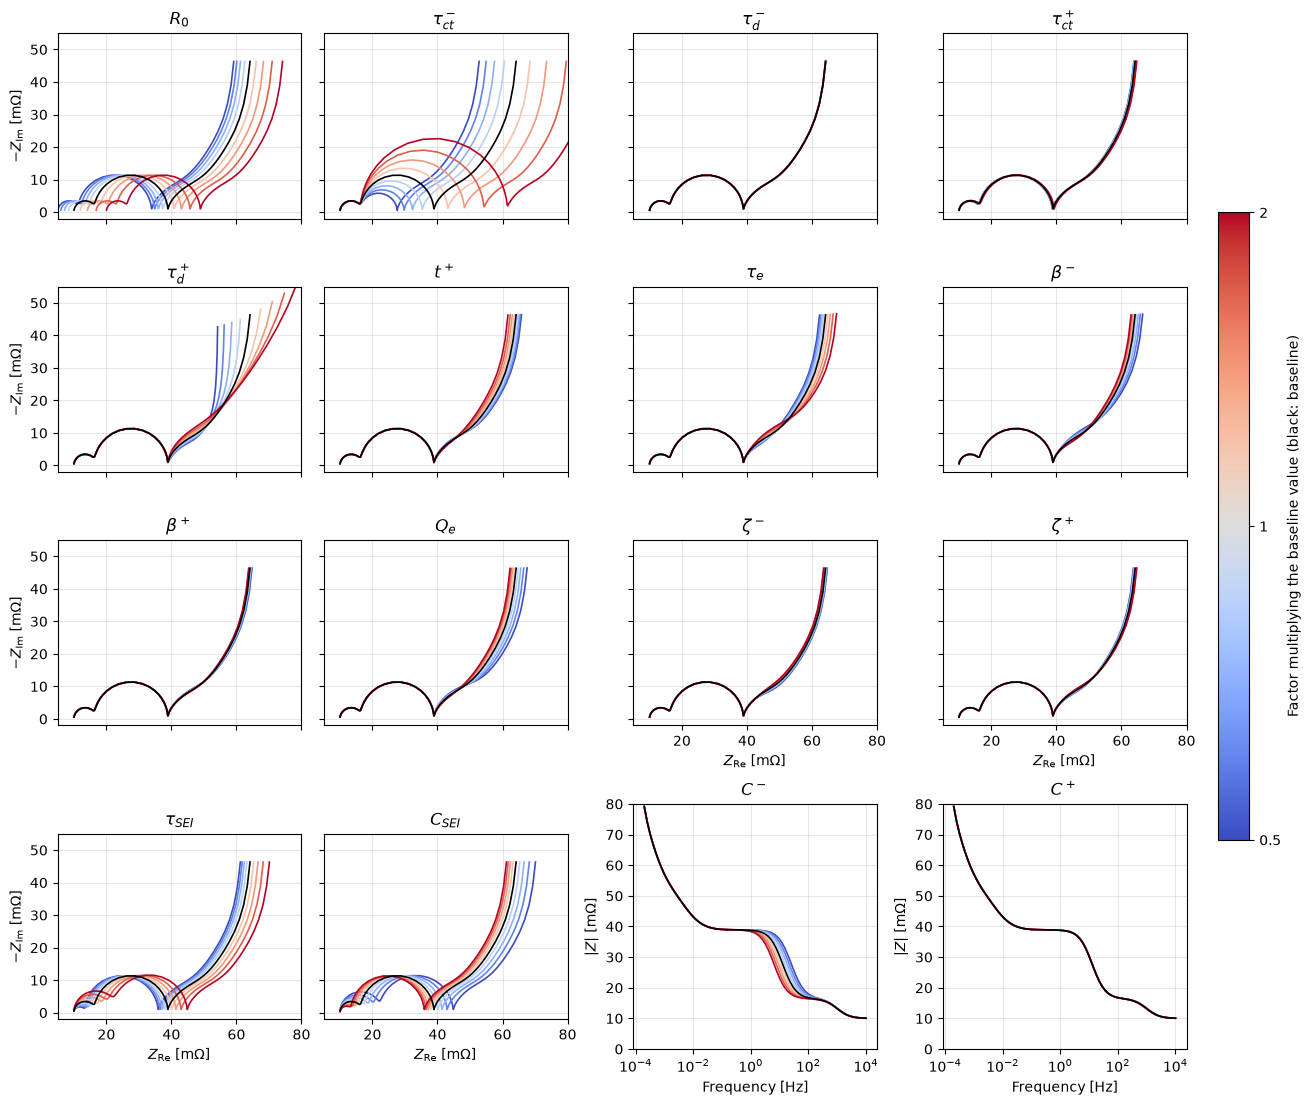

In [6]:
labels = {
    "R_0 [Ohm]": "$R_0$",
    "tau_ct- [s]": r"$\tau_{ct}^-$",
    "tau_d- [s]": r"$\tau_d^-$",
    "tau_ct+ [s]": r"$\tau_{ct}^+$",
    "tau_d+ [s]": r"$\tau_d^+$",
    "t+": "$t^+$",
    "tau_e [s]": r"$\tau_e$",
    "beta-": r"$\beta^-$",
    "beta+": r"$\beta^+$",
    "Q_e [A.s]": "$Q_e$",
    "zeta-": r"$\zeta^-$",
    "zeta+": r"$\zeta^+$",
    "tau_SEI [s]": r"$\tau_{SEI}$",
    "C_SEI [F]": "$C_{SEI}$",
    "C- [F]": "$C^-$",
    "C+ [F]": "$C^+$",
}
bode_groups = ["C- [F]", "C+ [F]"]
factors = np.logspace(np.log10(0.5), np.log10(2), 9)
colors = plt.get_cmap("coolwarm")(np.linspace(0, 1, len(factors)))
colors[len(factors) // 2] = (0, 0, 0, 1)  # baseline in black
# Draw the baseline last so it stays visible where the curves overlap
plot_order = [i for i in range(len(factors)) if i != len(factors) // 2]
plot_order.append(len(factors) // 2)

fig, axes = plt.subplots(4, 4, figsize=(13, 11), layout="constrained")
for i, (ax, (group, label)) in enumerate(zip(axes.flat, labels.items(), strict=True)):
    row, col = divmod(i, 4)
    for j in plot_order:
        z, color = impedance(group, factors[j]), colors[j]
        if group in bode_groups:
            ax.semilogx(frequencies, np.abs(z) * 1e3, color=color, lw=1.2)
        else:
            ax.plot(z.real * 1e3, -z.imag * 1e3, color=color, lw=1.2)
    ax.set_title(label)
    ax.grid(alpha=0.3)
    if group in bode_groups:
        ax.set(xlabel="Frequency [Hz]", ylabel=r"$|Z|$ [m$\Omega$]", ylim=(0, 80))
        continue
    ax.set(xlim=(5, 80), ylim=(-2, 55), aspect="equal")
    bottom = row == 3 or (row == 2 and col >= 2)
    ax.tick_params(labelleft=col == 0, labelbottom=bottom)
    if col == 0:
        ax.set_ylabel(r"$-Z_\mathrm{Im}$ [m$\Omega$]")
    if bottom:
        ax.set_xlabel(r"$Z_\mathrm{Re}$ [m$\Omega$]")

colorbar = fig.colorbar(
    plt.cm.ScalarMappable(
        cmap="coolwarm", norm=plt.matplotlib.colors.LogNorm(factors[0], factors[-1])
    ),
    ax=axes,
    shrink=0.6,
    pad=0.02,
)
colorbar.set_label("Factor multiplying the baseline value (black: baseline)")
colorbar.set_ticks([0.5, 1, 2], labels=["0.5", "1", "2"])
colorbar.ax.minorticks_off()
plt.show()

A few patterns stand out:

- $R_0$ shifts the whole spectrum along the real axis.
- $\tau_{ct}^-$ sets the size of the main charge-transfer arc. $C^-$ moves that arc in frequency: in the Bode plot, the drop in $|Z|$ from the charge-transfer arc shifts to lower frequency as $C^-$ increases. With the `Chen2020` parameters the positive-electrode kinetics are fast, so $\tau_{ct}^+$ and $C^+$ barely matter.
- The diffusion and electrolyte groups ($\tau_d^\pm$, $\tau_e$, $\beta^\pm$, $\zeta^\pm$, $Q_e$, $t^+$) only change the low-frequency tail.
- Increasing $\tau_{SEI}$ at fixed $C_{SEI}$ increases the film resistance $R_{SEI} = \tau_{SEI} / C_{SEI}$. The SEI arc grows and moves to lower frequency, towards the charge-transfer arc.
- Increasing $C_{SEI}$ at fixed $\tau_{SEI}$ decreases $R_{SEI}$, so the SEI arc shrinks while staying at the same frequency.

Because the SEI arc has its own time constant, the SEI film changes the shape of the spectrum, not just the size of the charge-transfer arc. Without the film capacitance (`"SEI film capacitance": "false"`), the film resistance would simply add to the charge-transfer arc.

## A wider sweep of the SEI groups

The SEI properties are uncertain over orders of magnitude, so the factor-of-two range above only hints at what the SEI can do to the spectrum. Below we scale $\tau_{SEI}$ and $C_{SEI}$ from 0.1 to 10 times their baseline values.

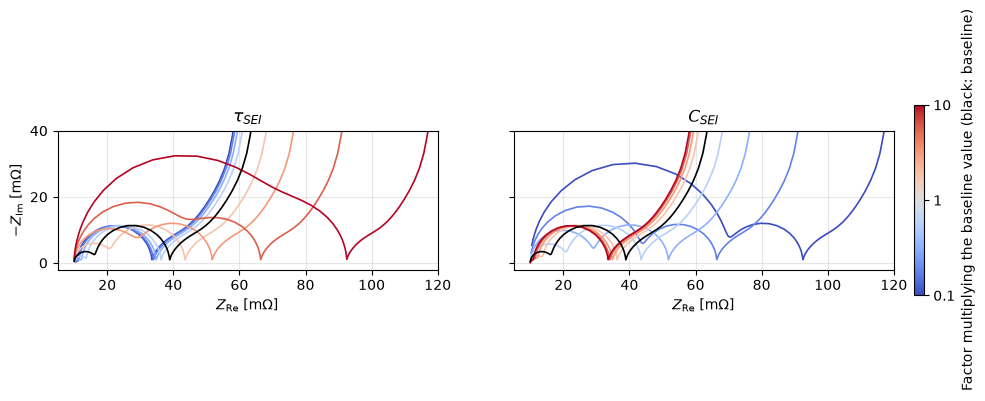

In [7]:
wide_factors = np.logspace(-1, 1, 9)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, group in zip(axes, ["tau_SEI [s]", "C_SEI [F]"], strict=True):
    for j in plot_order:
        z = impedance(group, wide_factors[j])
        ax.plot(z.real * 1e3, -z.imag * 1e3, color=colors[j], lw=1.2)
    ax.set_title(labels[group])
    ax.set_aspect("equal")
    ax.set_xlabel(r"$Z_\mathrm{Re}$ [m$\Omega$]")
    ax.grid(alpha=0.3)
axes[0].set(xlim=(5, 120), ylim=(-2, 40), ylabel=r"$-Z_\mathrm{Im}$ [m$\Omega$]")
axes[1].set_xlim(5, 120)
colorbar = fig.colorbar(
    plt.cm.ScalarMappable(
        cmap="coolwarm",
        norm=plt.matplotlib.colors.LogNorm(wide_factors[0], wide_factors[-1]),
    ),
    ax=axes,
    shrink=0.55,
    pad=0.02,
)
colorbar.set_label("Factor multiplying the baseline value (black: baseline)")
colorbar.set_ticks([0.1, 1, 10], labels=["0.1", "1", "10"])
colorbar.ax.minorticks_off()
plt.show()

Increasing $\tau_{SEI}$ (here, the resistivity) grows the film resistance and slows the film down. At large values the SEI arc becomes larger than the charge-transfer arc, and once its time constant approaches the charge-transfer one the two merge into a single, larger arc. Decreasing $C_{SEI}$ (here, a thicker film) grows the film resistance at a fixed time constant, so the SEI arc grows while staying at high frequency and remaining distinct from the charge-transfer arc.

## References

The relevant papers for this notebook are:

In [8]:
pybamm.print_citations()

[1] Joel A. E. Andersson, Joris Gillis, Greg Horn, James B. Rawlings, and Moritz Diehl. CasADi – A software framework for nonlinear optimization and optimal control. Mathematical Programming Computation, 11(1):1–36, 2019. doi:10.1007/s12532-018-0139-4.
[2] Von DAG Bruggeman. Berechnung verschiedener physikalischer konstanten von heterogenen substanzen. i. dielektrizitätskonstanten und leitfähigkeiten der mischkörper aus isotropen substanzen. Annalen der physik, 416(7):636–664, 1935.
[3] Chang-Hui Chen, Ferran Brosa Planella, Kieran O'Regan, Dominika Gastol, W. Dhammika Widanage, and Emma Kendrick. Development of Experimental Techniques for Parameterization of Multi-scale Lithium-ion Battery Models. Journal of The Electrochemical Society, 167(8):080534, 2020. doi:10.1149/1945-7111/ab9050.
[4] Noël Hallemans, Nicola E Courtier, Colin P Please, Brady Planden, Rishit Dhoot, Robert Timms, S Jon Chapman, David Howey, and Stephen R Duncan. Physics-based battery model parametrisation from impe